# 04 - Modelling
## 1. Data loading and feature setup

In [1]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

df = pd.read_csv('../data/processed/hourly_demand_weather.csv', parse_dates=['date'])

TARGET = 'trips'
TIME = ['hour_sin', 'hour_cos', 'is_weekend', 'is_holiday']
LAGS = ['lag_24', 'lag_168', 'roll_24']
WEATHER = ['temperature_2m', 'precipitation', 'wind_speed_10m', 'relative_humidity_2m', 'is_rain']
sets = {'time': TIME, 'time+lags': TIME + LAGS, 'time+lags+weather': TIME + LAGS + WEATHER}

use = df[df['exclude'] == 0]
train = use[use['split'] == 'train']
val = use[use['split'] == 'val']
test = use[use['split'] == 'test']
print(len(train), len(val), len(test))

10058 2232 2304


## 2. Evaluation function

In [2]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(y_true, y_pred): # all models are compared with the same metrics (MAE, RMSE, R²). Predictions are clipped at zero because trips cannot be negative
    y_pred = np.clip(y_pred, 0, None)
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

## 3. Model 0: baseline (same hour last week)

In [3]:
for name, part in [('val', val), ('test', test)]: # The simplest forecast sets the minimum accuracy that all models must beat
    print(name, evaluate(part[TARGET], part['lag_168']))

val {'MAE': 8.376792114695341, 'RMSE': np.float64(13.5033349126592), 'R2': 0.6166396580855378}
test {'MAE': 7.081597222222222, 'RMSE': np.float64(11.899244257047961), 'R2': 0.766407353231628}


## 4. Model 1: Ridge regression
Simple, interpretable linear model. City is one-hot encoded and numeric features are scaled inside the pipeline, fitted on the training set only. Feature groups are added step by step (time, lags, weather).

In [4]:
def make_ridge(num_cols, alpha):
    prep = ColumnTransformer([
        ('city', OneHotEncoder(handle_unknown='ignore'), ['city']),
        ('num', StandardScaler(), num_cols),
    ])
    return Pipeline([('prep', prep), ('model', Ridge(alpha=alpha))])

In [5]:
rows = []
for name, cols in sets.items():
    for a in [0.1, 1, 10, 100]:
        m = make_ridge(cols, a).fit(train[['city'] + cols], train[TARGET])
        res = evaluate(val[TARGET], m.predict(val[['city'] + cols]))
        rows.append({'model': 'Ridge', 'features': name, 'alpha': a, **res})

ridge_val = pd.DataFrame(rows).round(2)
ridge_val

,model,features,alpha,MAE,RMSE,R2
0,Ridge,time,0.1,13.69,18.96,0.24
1,Ridge,time,1.0,13.69,18.95,0.24
2,Ridge,time,10.0,13.67,18.91,0.25
3,Ridge,time,100.0,13.53,18.51,0.28
4,Ridge,time+lags,0.1,6.53,10.06,0.79
5,Ridge,time+lags,1.0,6.53,10.06,0.79
6,Ridge,time+lags,10.0,6.53,10.07,0.79
7,Ridge,time+lags,100.0,6.53,10.09,0.79
8,Ridge,time+lags+weather,0.1,6.89,10.19,0.78
9,Ridge,time+lags+weather,1.0,6.89,10.19,0.78


## 5. Model 2: Random Forest
Captures non-linear pattern such as the two daily peaks and interactions between hour, weekday and level of demand

In [6]:
def make_rf(num_cols, max_depth, min_leaf):
    prep = ColumnTransformer([
        ('city', OneHotEncoder(handle_unknown='ignore'), ['city']),
        ('num', 'passthrough', num_cols),
    ])
    rf = RandomForestRegressor(n_estimators=200, max_depth=max_depth,
                               min_samples_leaf=min_leaf, n_jobs=-1, random_state=42)
    return Pipeline([('prep', prep), ('model', rf)])

In [7]:
rows = []
for name, cols in sets.items():
    for depth in [8, None]:
        for leaf in [5, 20]:
            m = make_rf(cols, depth, leaf).fit(train[['city'] + cols], train[TARGET])
            res = evaluate(val[TARGET], m.predict(val[['city'] + cols]))
            rows.append({'model': 'Random forest', 'features': name,
                         'max_depth': depth, 'min_leaf': leaf, **res})

rf_val = pd.DataFrame(rows).round(2)
rf_val

,model,features,max_depth,min_leaf,MAE,RMSE,R2
0,Random forest,time,8.0,5,11.62,17.61,0.35
1,Random forest,time,8.0,20,11.65,17.59,0.35
2,Random forest,time,NaN,5,11.31,17.36,0.37
3,Random forest,time,NaN,20,11.42,17.40,0.36
4,Random forest,time+lags,8.0,5,6.54,10.31,0.78
5,Random forest,time+lags,8.0,20,6.45,10.13,0.78
6,Random forest,time+lags,NaN,5,6.60,10.51,0.77
7,Random forest,time+lags,NaN,20,6.38,10.09,0.79
8,Random forest,time+lags+weather,8.0,5,6.49,10.14,0.78
9,Random forest,time+lags+weather,8.0,20,6.46,10.06,0.79


## 6. Model 3: XGBoost 
Builds trees one after another, each correcting the errors of the previous ones. XGBoost adds regularisation and is a standard choice for tabular data.

In [8]:
def make_xgb(num_cols, lr, depth):
    prep = ColumnTransformer([
        ('city', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['city']),
        ('num', 'passthrough', num_cols),
    ])
    xgb = XGBRegressor(n_estimators=300, learning_rate=lr, max_depth=depth,
                       subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                       n_jobs=-1, random_state=42)
    return Pipeline([('prep', prep), ('model', xgb)])

In [9]:
rows = []
for name, cols in sets.items():
    for lr in [0.03, 0.1]:
        for depth in [3, 5]:
            m = make_xgb(cols, lr, depth).fit(train[['city'] + cols], train[TARGET])
            res = evaluate(val[TARGET], m.predict(val[['city'] + cols]))
            rows.append({'model': 'XGBoost', 'features': name,
                         'learning_rate': lr, 'max_depth': depth, **res})

xgb_val = pd.DataFrame(rows).round(2)
xgb_val

,model,features,learning_rate,max_depth,MAE,RMSE,R2
0,XGBoost,time,0.03,3,11.90,17.66,0.34
1,XGBoost,time,0.03,5,11.58,17.57,0.35
2,XGBoost,time,0.10,3,11.79,17.76,0.34
3,XGBoost,time,0.10,5,11.43,17.52,0.35
4,XGBoost,time+lags,0.03,3,6.40,10.02,0.79
5,XGBoost,time+lags,0.03,5,6.49,10.36,0.77
6,XGBoost,time+lags,0.10,3,6.59,10.44,0.77
7,XGBoost,time+lags,0.10,5,6.89,11.27,0.73
8,XGBoost,time+lags+weather,0.03,3,6.31,9.73,0.80
9,XGBoost,time+lags+weather,0.03,5,6.10,9.66,0.80


## 7. Comparison of models (validation)

In [10]:
all_val = pd.concat([ridge_val, rf_val, xgb_val], ignore_index=True)
best = all_val.loc[all_val.groupby(['model', 'features'])['MAE'].idxmin()]
best[['model', 'features', 'MAE', 'RMSE', 'R2']].sort_values('MAE')

,model,features,MAE,RMSE,R2
33,XGBoost,time+lags+weather,6.10,9.66,0.80
23,Random forest,time+lags+weather,6.34,9.98,0.79
19,Random forest,time+lags,6.38,10.09,0.79
28,XGBoost,time+lags,6.40,10.02,0.79
4,Ridge,time+lags,6.53,10.06,0.79
11,Ridge,time+lags+weather,6.78,10.13,0.78
14,Random forest,time,11.31,17.36,0.37
27,XGBoost,time,11.43,17.52,0.35
3,Ridge,time,13.53,18.51,0.28


## 8. Hyperparameter tuning

In [11]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit

trval = pd.concat([train, val])
split = PredefinedSplit(np.r_[np.full(len(train), -1), np.zeros(len(val))])

In [12]:
search_space = {
    'Ridge': (lambda c: make_ridge(c, 1.0),
              {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]}),
    'Random forest': (lambda c: make_rf(c, None, 20),
              {'model__max_depth': [8, 12, 20, None],
               'model__min_samples_leaf': [5, 20, 50],
               'model__max_features': [0.5, 1.0]}),
    'XGBoost': (lambda c: make_xgb(c, 0.03, 5),
              {'model__learning_rate': [0.01, 0.03, 0.1],
               'model__max_depth': [3, 5, 7],
               'model__n_estimators': [300, 600],
               'model__reg_lambda': [1, 10]}),
}

In [13]:
results, trials = [], []

for fname, cols in sets.items():
    X = trval[['city'] + cols]
    y = trval[TARGET]
    for mname, (builder, grid) in search_space.items():
        gs = GridSearchCV(builder(cols), grid, cv=split,
                          scoring='neg_mean_absolute_error',
                          refit=False, n_jobs=1)
        gs.fit(X, y)

        best_params = gs.best_params_
        model = builder(cols).set_params(**best_params).fit(train[['city'] + cols], train[TARGET])
        res = evaluate(val[TARGET], model.predict(val[['city'] + cols]))
        results.append({'model': mname, 'features': fname, 'best_params': best_params, **res})

        t = pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score']]
        t['val_MAE'] = -t.pop('mean_test_score')
        t['model'], t['features'] = mname, fname
        trials.append(t)

tuned = pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)
tuned.round(2)

,model,features,best_params,MAE,RMSE,R2
0,XGBoost,time+lags+weather,"{'model__learning_rate': 0.01, 'model__max_dep...",6.10,9.62,0.81
1,Random forest,time+lags+weather,"{'model__max_depth': None, 'model__max_feature...",6.14,9.66,0.80
2,Random forest,time+lags,"{'model__max_depth': None, 'model__max_feature...",6.28,9.88,0.79
3,XGBoost,time+lags,"{'model__learning_rate': 0.01, 'model__max_dep...",6.36,10.03,0.79
4,Ridge,time+lags,{'model__alpha': 100},6.53,10.09,0.79
5,Ridge,time+lags+weather,{'model__alpha': 1000},6.75,10.28,0.78
6,Random forest,time,"{'model__max_depth': 20, 'model__max_features'...",11.31,17.36,0.37
7,XGBoost,time,"{'model__learning_rate': 0.1, 'model__max_dept...",11.35,17.44,0.36
8,Ridge,time,{'model__alpha': 1000},13.15,17.12,0.38


In [14]:
trials_all = pd.concat(trials, ignore_index=True)
trials_all.groupby(['model', 'features'])['val_MAE'].agg(['min', 'median', 'max']).round(2)

min  median    max
model         features                               
Random forest time               11.31   11.53  11.77
              time+lags           6.28    6.39   6.60
              time+lags+weather   6.14    6.34   6.49
Ridge         time               13.23   14.08  14.09
              time+lags           6.59    6.59   6.70
              time+lags+weather   6.95    7.22   7.23
XGBoost       time               11.35   11.54  11.95
              time+lags           6.36    6.64   7.46
              time+lags+weather   6.10    6.27   7.03

In [15]:
before = best[['model', 'features', 'MAE']].rename(columns={'MAE': 'MAE_initial'})
after = tuned[['model', 'features', 'MAE']].rename(columns={'MAE': 'MAE_tuned'})
cmp = before.merge(after, on=['model', 'features'])
cmp['change_%'] = ((cmp['MAE_tuned'] / cmp['MAE_initial'] - 1) * 100).round(1)
cmp.sort_values('MAE_tuned').round(2)

,model,features,MAE_initial,MAE_tuned,change_%
8,XGBoost,time+lags+weather,6.10,6.10,-0.1
2,Random forest,time+lags+weather,6.34,6.14,-3.1
1,Random forest,time+lags,6.38,6.28,-1.6
7,XGBoost,time+lags,6.40,6.36,-0.7
4,Ridge,time+lags,6.53,6.53,-0.1
5,Ridge,time+lags+weather,6.78,6.75,-0.4
0,Random forest,time,11.31,11.31,-0.0
6,XGBoost,time,11.43,11.35,-0.7
3,Ridge,time,13.53,13.15,-2.8


## 9. Final evaluation on the test set

In [16]:
def pick_final(mname):
    row = tuned[tuned['model'] == mname].iloc[0]
    cols = sets[row['features']]
    model = search_space[mname][0](cols).set_params(**row['best_params'])
    return model, cols, row['features']

final_models = {m: pick_final(m) for m in search_space}

rows = [{'model': 'Baseline (last week)', 'features': '-',
         **evaluate(test[TARGET], test['lag_168'])}]
test_preds = {}
for name, (model, cols, fset) in final_models.items():
    model.fit(trval[['city'] + cols], trval[TARGET])
    pred = np.clip(model.predict(test[['city'] + cols]), 0, None)
    test_preds[name] = pred
    rows.append({'model': name, 'features': fset, **evaluate(test[TARGET], pred)})

test_results = pd.DataFrame(rows).round(2)
test_results

,model,features,MAE,RMSE,R2
0,Baseline (last week),-,7.08,11.90,0.77
1,Ridge,time+lags,6.02,9.27,0.86
2,Random forest,time+lags+weather,5.97,9.91,0.84
3,XGBoost,time+lags+weather,5.96,9.90,0.84


## 10. Error analysis

### 10.1 Error by city, hour, rain and weekend

In [ ]:
def by_group(df, y_pred, group): 
    d = pd.DataFrame({'g': df[group].values, 'y': df[TARGET].values, 'p': y_pred})
    d['abs'] = (d['y'] - d['p']).abs()
    out = d.groupby('g').agg(MAE=('abs', 'mean'), mean_demand=('y', 'mean'))
    out['MAE_pct_of_mean'] = (out['MAE'] / out['mean_demand'] * 100).round(1)
    return out.round(2)

In [18]:
p = test_preds['XGBoost']
for g in ['city', 'hour', 'is_rain', 'is_weekend']:
    print('Error by', g)
    print(by_group(test, p, g), '\n')

Error by city
                 MAE  mean_demand  MAE_pct_of_mean
g                                                 
Badalona        5.54        29.40             18.8
Brno            4.05        11.68             34.7
Frankfurt       6.13        18.42             33.3
Frydek-Mistek   2.85         6.71             42.5
Havirov         4.92        13.96             35.2
Leon            6.49        22.93             28.3
Opava           4.00        12.86             31.1
Ostrava        13.75        54.21             25.4 

Error by hour
      MAE  mean_demand  MAE_pct_of_mean
g                                      
0    2.97         5.66             52.5
1    2.70         3.99             67.8
2    2.05         2.70             76.1
3    1.61         1.75             92.0
4    1.69         2.31             73.0
5    2.51         5.88             42.7
6    3.87        10.28             37.7
7    6.49        20.85             31.1
8    6.20        22.55             27.5
9    5.25        19.

### 10.2 Bias by city

In [ ]:
def bias_by_group(df, y_pred, group): 
    d = pd.DataFrame({'g': df[group].values, 'y': df[TARGET].values, 'p': y_pred})
    d['err'] = d['p'] - d['y']
    out = d.groupby('g').agg(bias=('err', 'mean'), mean_demand=('y', 'mean'))
    out['bias_pct_of_mean'] = (out['bias'] / out['mean_demand'] * 100).round(1)
    return out.round(2)

bias_by_group(test, test_preds['XGBoost'], 'city')

,bias,mean_demand,bias_pct_of_mean
g,,,
Badalona,0.03,29.40,0.1
Brno,1.27,11.68,10.9
Frankfurt,1.22,18.42,6.6
Frydek-Mistek,1.16,6.71,17.3
Havirov,-1.92,13.96,-13.7
Leon,1.76,22.93,7.7
Opava,0.47,12.86,3.6
Ostrava,-8.43,54.21,-15.6


In [20]:
chk_test = pd.DataFrame({
    'trval_mean': trval.groupby('city')[TARGET].mean(),
    'test_mean': test.groupby('city')[TARGET].mean(),
}).join(bias_by_group(test, test_preds['XGBoost'], 'city')['bias_pct_of_mean']).round(2)
chk_test

,trval_mean,test_mean,bias_pct_of_mean
city,,,
Badalona,25.41,29.40,0.1
Brno,23.03,11.68,10.9
Frankfurt,15.57,18.42,6.6
Frydek-Mistek,16.11,6.71,17.3
Havirov,17.46,13.96,-13.7
Leon,17.69,22.93,7.7
Opava,19.12,12.86,3.6
Ostrava,60.44,54.21,-15.6


### 10.3 Actual vs forecast

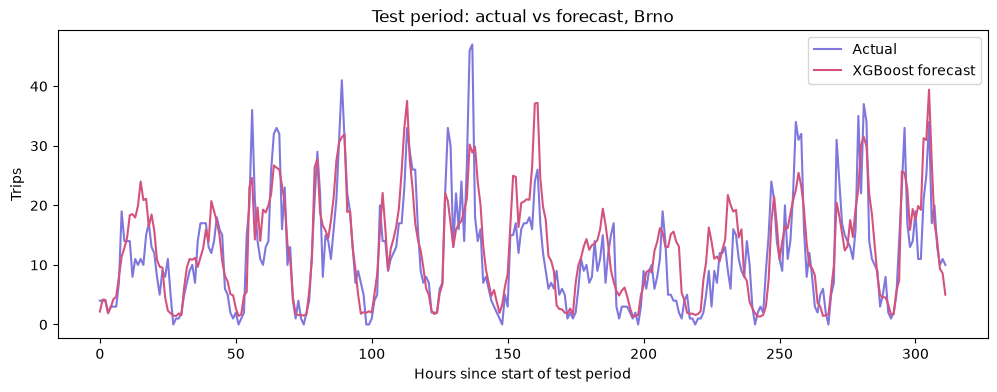

In [ ]:
import matplotlib.pyplot as plt

c = 'Brno'
m = (test['city'] == c).values
plt.figure(figsize=(12, 4))
plt.plot(test.loc[m, TARGET].values, label='Actual', color='#7F77DD')
plt.plot(test_preds['XGBoost'][m], label='XGBoost forecast', color='#D4537E')
plt.title(f'Test period: actual vs forecast, {c}')
plt.xlabel('Hours since start of test period')
plt.ylabel('Trips')
plt.legend()
plt.show()


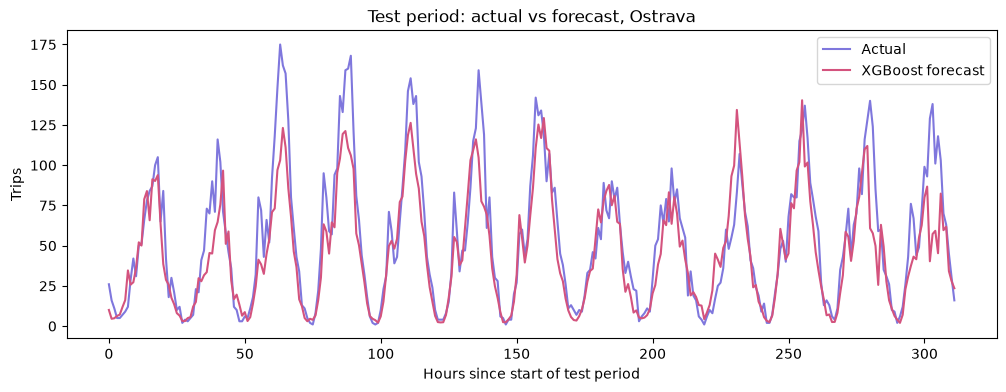

In [24]:
import matplotlib.pyplot as plt

c = 'Ostrava'
m = (test['city'] == c).values
plt.figure(figsize=(12, 4))
plt.plot(test.loc[m, TARGET].values, label='Actual', color='#7F77DD')
plt.plot(test_preds['XGBoost'][m], label='XGBoost forecast', color='#D4537E')
plt.title(f'Test period: actual vs forecast, {c}')
plt.xlabel('Hours since start of test period')
plt.ylabel('Trips')
plt.legend()
plt.show()

### 10.4 Effects of weather on the test set
Supplementary analysis only. The final model was selected on validation MAE, not on these results

In [ ]:
def tuned_params(mname, fname):
    return tuned[(tuned['model'] == mname) & (tuned['features'] == fname)].iloc[0]['best_params']

rows = []
for mname in ['Ridge', 'Random forest', 'XGBoost']:
    for fname in ['time+lags', 'time+lags+weather']:
        cols = sets[fname]
        m = search_space[mname][0](cols).set_params(**tuned_params(mname, fname))
        m.fit(trval[['city'] + cols], trval[TARGET])
        pred = np.clip(m.predict(test[['city'] + cols]), 0, None)
        rows.append({'model': mname, 'features': fname, **evaluate(test[TARGET], pred)})

pd.DataFrame(rows).round(2)

,model,features,MAE,RMSE,R2
0,Ridge,time+lags,6.02,9.27,0.86
1,Ridge,time+lags+weather,6.32,9.72,0.84
2,Random forest,time+lags,5.80,9.17,0.86
3,Random forest,time+lags+weather,5.97,9.91,0.84
4,XGBoost,time+lags,5.74,8.99,0.87
5,XGBoost,time+lags+weather,5.96,9.90,0.84
